<img src="Bilder/ost_logo.png" width="240" align="right"/>
<div style="text-align: left"> <b> Machine Learning Projekt</b> <br> HS 2025 <br> <a href="mailto:ryan.mikus@ost.ch"> Ryan Mikus </a> und <a href="mailto:ilija.amato@ost.ch"> Ilija Amato </a> </div>

# 5. Modellierung


In [1]:
# Zelle 1: Imports & Konfiguration
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, ParameterGrid
from sklearn.metrics import roc_auc_score

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.base import clone

from pairs_trading import data_io as io
from pairs_trading import eda
from pairs_trading import features

# Data input
DATA_DIR = "Daten"
BASENAME = "market_data_cleaned"

# Windows
LOOKBACK_PAIR_DAYS = 10      # für Pair-Selektion (Korrelation + Cointegration)
LOOKBACK_TRAIN_DAYS = 10     # Rolling Train-Window (ML-Fit)

# Pair Selection
TOP_CORR_PAIRS = 50        # Top-N nach |corr| (statt Threshold)
TOP_DAILY_PAIRS = 5        # Top-N nach Cointegration-Consistency
P_COINTEGRATION = 0.05       # Signifikanzschwelle für "sig day" bei Cointegration

# Caching / Rebalance
REBALANCE_EVERY_N_DAYS = 5   # ungefähr wöchentlich (Handelstage)
CACHE_DIR = Path("cache_pairs")
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# Tuning
TUNING_DAY_STRIDE = 5   # jeder 5. Test-Tag

# k (Horizon) wird später optimiert (global)
K_CANDIDATES = [3, 5, 10, 15]
K_FIXED = 5
best_k = K_FIXED

# Feature windows (wie festgelegt)
RSI_W = 14
Z_W = 60
VOL_W = 20

RANDOM_STATE = 42
N_JOBS = -1


In [2]:
# Zelle 2: Gesäuberte Daten laden
df = io.load_preprocessed_data(
    data_dir="Daten",
    basename=BASENAME
)


[Preprocessed Data Load]
Pfad: Daten\market_data_cleaned.parquet

[Preprocessed Data]
Shape: (7490150, 7)
Spalten: ['datetime', 'symbol', 'open', 'high', 'low', 'volume', 'close_filled']

Head:
                   datetime symbol        open        high         low  \
0 2025-11-07 14:30:00+00:00      A  146.520004  147.119995  145.729996   
1 2025-11-07 14:31:00+00:00      A         NaN         NaN         NaN   
2 2025-11-07 14:32:00+00:00      A  146.089996  146.089996  146.089996   
3 2025-11-07 14:33:00+00:00      A         NaN         NaN         NaN   
4 2025-11-07 14:34:00+00:00      A  146.049698  146.049698  146.049698   

    volume  close_filled  
0  13361.0    145.729996  
1      NaN    145.909996  
2    427.0    146.089996  
3      NaN    146.069847  
4   1387.0    146.049698  


In [3]:
# Zelle 3: Unnötige Spalten droppen
df = df[["datetime", "symbol", "close_filled"]].copy()
df.head()

,datetime,symbol,close_filled
0,2025-11-07 14:30:00+00:00,A,145.729996
1,2025-11-07 14:31:00+00:00,A,145.909996
2,2025-11-07 14:32:00+00:00,A,146.089996
3,2025-11-07 14:33:00+00:00,A,146.069847
4,2025-11-07 14:34:00+00:00,A,146.049698


In [4]:
# Zelle 4: Long -> Wide (close_filled) und Basis-Sanity
df = df.copy()
df["datetime"] = pd.to_datetime(df["datetime"], utc=True, errors="coerce")
df = df.dropna(subset=["datetime", "symbol", "close_filled"]).sort_values(["datetime", "symbol"])

prices_wide = (
    df.pivot(index="datetime", columns="symbol", values="close_filled")
    .sort_index()
)

print("prices_wide shape:", prices_wide.shape)
print("date range:", prices_wide.index.min(), "->", prices_wide.index.max())


prices_wide shape: (15638, 479)
date range: 2025-11-07 14:30:00+00:00 -> 2026-01-09 21:00:00+00:00


In [5]:
# Zelle 5: Log-Preise (Input für Cointegration/Features)
log_prices = np.log(prices_wide).dropna(how="all")
print("log_prices shape:", log_prices.shape)

log_prices shape: (15638, 479)


In [6]:
# Zelle 6: Hilfsfunktionen (Pair-Ranking, Auswahl, Feature/Label-Build + Cache)
def _upper_triangle_pairs_from_corr(corr: pd.DataFrame, top_n: int) -> list:
    """Top-N Paare nach |corr| aus der oberen Dreiecksmatrix."""
    cols = corr.columns
    pairs = []
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            v = corr.iat[i, j]
            if pd.notna(v):
                pairs.append((cols[i], cols[j], float(abs(v))))
    pairs.sort(key=lambda x: x[2], reverse=True)
    return [(a, b) for a, b, _ in pairs[:top_n]]


def select_pairs_for_day(
    log_prices_window: pd.DataFrame,
    top_corr_pairs: int = TOP_CORR_PAIRS,
    top_daily_pairs: int = TOP_DAILY_PAIRS,
    p_thresh: float = P_COINTEGRATION,
) -> pd.DataFrame:
    """
    1) Korrelation (Top-N nach |corr| auf Returns)
    2) Cointegration p-values pro Tag
    3) Ranking nach consistency + mean_p
    Returns: DataFrame (mind. symbol1, symbol2) der Top-Paare
    """
    rets = log_prices_window.diff().dropna(how="all")
    corr = rets.corr(method="pearson")
    corr_pairs = _upper_triangle_pairs_from_corr(corr, top_n=top_corr_pairs)

    daily_coint = eda.compute_daily_cointegration(
        log_prices_window,
        corr_pairs,
        min_obs_per_day=30,
        sort_index=True,
        sort_symbols_in_pair=False,  # Orientierung nicht zerstören
        verbose=False,
    )
    pair_stats = eda.compute_pair_stats(daily_coint, p_thresh=p_thresh)
    top_consistency, _ = eda.rank_pairs(pair_stats, top_n=top_daily_pairs)

    return top_consistency


def _cache_path_for_rebalance_day(rebalance_day):
    """
    Cache-Datei eindeutig machen anhand:
    - rebalance day
    - LOOKBACK_PAIR_DAYS
    - TOP_CORR_PAIRS / TOP_DAILY_PAIRS
    - P_COINTEGRATION
    """
    d = pd.to_datetime(rebalance_day).strftime("%Y%m%d")
    fname = (
        f"pairs_{d}"
        f"_lb{LOOKBACK_PAIR_DAYS}"
        f"_corr{TOP_CORR_PAIRS}"
        f"_top{TOP_DAILY_PAIRS}"
        f"_p{str(P_COINTEGRATION).replace('.', '')}.pkl"
    )
    return CACHE_DIR / fname


def get_pairs_for_test_day(day, all_days: pd.Index, log_prices: pd.DataFrame):
    """
    Paare werden nur alle REBALANCE_EVERY_N_DAYS neu berechnet.
    Für jeden Test-Tag wird ein 'rebalance_day' (Block-Anfang) bestimmt.
    Dann:
      - Cache laden, falls vorhanden
      - sonst berechnen aus LOOKBACK_PAIR_DAYS vor rebalance_day und cachen
    """
    idx_day = all_days.get_loc(day)

    # Block-Start (Rebalance Day) bestimmen
    block_start_idx = (idx_day // REBALANCE_EVERY_N_DAYS) * REBALANCE_EVERY_N_DAYS
    rebalance_day = all_days[block_start_idx]

    path = _cache_path_for_rebalance_day(rebalance_day)
    if path.exists():
        top_pairs_df = pd.read_pickle(path)
        return rebalance_day, top_pairs_df

    # Pair-Window: LOOKBACK_PAIR_DAYS vor rebalance_day (exkl. rebalance_day)
    idx_rb = all_days.get_loc(rebalance_day)
    pair_days = all_days[idx_rb - LOOKBACK_PAIR_DAYS : idx_rb]

    lp_pair = log_prices.loc[log_prices.index.normalize().isin(pair_days)].copy()

    top_pairs_df = select_pairs_for_day(
        lp_pair,
        top_corr_pairs=TOP_CORR_PAIRS,
        top_daily_pairs=TOP_DAILY_PAIRS,
        p_thresh=P_COINTEGRATION,
    )

    top_pairs_df.to_pickle(path)
    return rebalance_day, top_pairs_df


def build_Xy_from_feature_panel(
    panel: pd.DataFrame,
    k: int,
    return_meta: bool = False,
):
    """
    Label:
      y = 1, wenn |Z(t+k)| < |Z(t)|, sonst 0

    Optional:
      return_meta=True -> gibt Meta (datetime, pair) separat zurück
    """

    pair_names = panel.columns.get_level_values(1).unique().tolist()

    blocks = []
    for p in pair_names:
        dfp = panel.xs(p, axis=1, level=1).copy()
        dfp["pair"] = p
        blocks.append(dfp)

    long_df = (
        pd.concat(blocks, axis=0)
        .reset_index()
        .rename(columns={"index": "datetime"})
    )

    long_df = long_df.sort_values(["pair", "datetime"])

    z_col = f"Z_{Z_W}_spread"
    if z_col not in long_df.columns:
        raise ValueError(f"Missing column: {z_col}")

    z_now = long_df[z_col].astype(float)
    z_fut = long_df.groupby("pair")[z_col].shift(-k).astype(float)

    y = (z_fut.abs() < z_now.abs()).astype(int)

    X = long_df[
        [
            f"RSI_{RSI_W}_spread",
            f"Z_{Z_W}_spread",
            f"VOL_{VOL_W}_spread",
            "return_pct_spread",
        ]
    ].copy()

    valid = X.notna().all(axis=1) & y.notna()

    X = X.loc[valid].reset_index(drop=True)
    y = y.loc[valid].reset_index(drop=True)

    meta = None
    if return_meta:
        meta = (
            long_df.loc[valid, ["datetime", "pair"]]
            .reset_index(drop=True)
        )

    return X, y, meta

In [7]:
# Zelle 7: Liste der Handelstage & Walk-forward Setup
all_days = pd.Index(log_prices.index.normalize().unique()).sort_values()
print("n_days:", len(all_days), "| first:", all_days.min().date(), "| last:", all_days.max().date())

def _slice_by_days(df_wide: pd.DataFrame, days: pd.Index) -> pd.DataFrame:
    mask = df_wide.index.normalize().isin(days)
    return df_wide.loc[mask].copy()

# Starttag so wählen, dass beide Lookbacks möglich sind
min_required = max(LOOKBACK_PAIR_DAYS, LOOKBACK_TRAIN_DAYS)
start_idx = min_required
test_days = all_days[start_idx:]
print("walk-forward test days:", len(test_days))


n_days: 40 | first: 2025-11-07 | last: 2026-01-09
walk-forward test days: 30


In [8]:
# Zelle 8: Modelle (Pipelines) definieren

logreg = Pipeline([
    ("clf", LogisticRegression(
        max_iter=2000,
        solver="lbfgs",
        n_jobs=N_JOBS,
        random_state=RANDOM_STATE,
    ))
])

rf = Pipeline([
    ("clf", RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=10,
        n_jobs=N_JOBS,
        random_state=RANDOM_STATE,
        class_weight="balanced_subsample",
    ))
])

xgb = Pipeline([
    ("clf", XGBClassifier(
        n_estimators=400,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        random_state=RANDOM_STATE,
        n_jobs=0,            # xgboost erwartet hier int; 0 = alle Threads
        eval_metric="logloss",
        tree_method="hist",
    ))
])

# Soft Voting Ensemble (Meta-Ensemble über heterogene Learner)
vote_soft = VotingClassifier(
    estimators=[
        ("lr", clone(logreg)),
        ("rf", clone(rf)),
        ("xgb", clone(xgb)),
    ],
    voting="soft",
    n_jobs=N_JOBS,
)

models = {
    "LogReg": logreg,
    "RF": rf,
    "XGB": xgb,
    "VoteSoft": vote_soft,
}

In [9]:
# %%
# Zelle 8b: Vollständiger Walk-forward Run (für Reports & Plots)

def walk_forward_run(k: int, verbose: bool = True) -> pd.DataFrame:
    """
    Vollständiger Walk-forward über alle Modelle.
    Returns: DataFrame mit [day, model, auc, n_pairs, n_train, n_test]
    """
    records = []

    for day in test_days:
        idx_day = all_days.get_loc(day)

        train_days = all_days[idx_day - LOOKBACK_TRAIN_DAYS : idx_day]
        lp_train = _slice_by_days(log_prices, train_days)
        lp_test = _slice_by_days(log_prices, pd.Index([day]))

        _, top_pairs_df = get_pairs_for_test_day(day, all_days, log_prices)
        if top_pairs_df.empty:
            continue

        pairs = list(
            top_pairs_df[["symbol1", "symbol2"]]
            .itertuples(index=False, name=None)
        )

        panel_train = features.build_feature_panel(lp_train, pairs, RSI_W, Z_W, VOL_W)
        panel_test = features.build_feature_panel(lp_test, pairs, RSI_W, Z_W, VOL_W)

        X_train, y_train, _ = build_Xy_from_feature_panel(panel_train, k)
        X_test, y_test, _ = build_Xy_from_feature_panel(panel_test, k)

        if len(y_train) < 200 or len(y_test) < 50:
            continue

        for model_name, model in models.items():
            model.fit(X_train, y_train)

            proba = model.predict_proba(X_test)[:, 1]
            auc = roc_auc_score(y_test, proba)

            records.append({
                "day": pd.to_datetime(day),
                "model": model_name,
                "auc": float(auc),
                "n_pairs": len(pairs),
                "n_train": len(y_train),
                "n_test": len(y_test),
            })

        if verbose:
            best_auc = max(r["auc"] for r in records if r["day"] == pd.to_datetime(day))
            print(f"{day.date()} | best_auc={best_auc:.3f}")

    return pd.DataFrame(records)


In [10]:
# Zelle 9: Walk-forward Evaluator (full oder light via TUNING_DAY_STRIDE)
def walk_forward_score(
    k: int,
    model_name: str,
    day_stride: int = 1,
    verbose: bool = False,
) -> float:
    """
    Walk-forward AUC.
    - day_stride = 1  -> voller Walk-forward (kein Subsampling)
    - day_stride > 1  -> light / tuning mode
    """
    model = models[model_name]
    aucs = []

    for i, day in enumerate(test_days):
        if day_stride > 1 and i % day_stride != 0:
            continue

        idx_day = all_days.get_loc(day)
        train_days = all_days[idx_day - LOOKBACK_TRAIN_DAYS : idx_day]

        lp_train = _slice_by_days(log_prices, train_days)
        lp_test = _slice_by_days(log_prices, pd.Index([day]))

        _, top_pairs_df = get_pairs_for_test_day(day, all_days, log_prices)
        if top_pairs_df.empty:
            continue

        pairs = list(
            top_pairs_df[["symbol1", "symbol2"]]
            .itertuples(index=False, name=None)
        )

        panel_train = features.build_feature_panel(lp_train, pairs, RSI_W, Z_W, VOL_W)
        panel_test = features.build_feature_panel(lp_test, pairs, RSI_W, Z_W, VOL_W)

        X_train, y_train, _ = build_Xy_from_feature_panel(panel_train, k)
        X_test, y_test, _ = build_Xy_from_feature_panel(panel_test, k)

        if len(y_train) < 200 or len(y_test) < 50:
            continue

        model.fit(X_train, y_train)
        proba = model.predict_proba(X_test)[:, 1]
        aucs.append(roc_auc_score(y_test, proba))

    return float(np.mean(aucs)) if aucs else np.nan


In [13]:
# Zelle 12: Finaler Walk-forward Run mit best_k (für Reports/Plots)
final_scores = walk_forward_run(k=best_k, verbose=True)
display(final_scores.head())

final_summary = (
    final_scores.groupby("model")["auc"]
    .agg(["mean", "std", "count"])
    .sort_values("mean", ascending=False)
)
display(final_summary)


2025-11-21 | best_auc=0.721
2025-11-24 | best_auc=0.730
2025-11-25 | best_auc=0.728
2025-11-26 | best_auc=0.747
2025-12-01 | best_auc=0.721
2025-12-02 | best_auc=0.717
2025-12-03 | best_auc=0.723
2025-12-04 | best_auc=0.746
2025-12-05 | best_auc=0.706
2025-12-08 | best_auc=0.716
2025-12-09 | best_auc=0.721
2025-12-10 | best_auc=0.744
2025-12-11 | best_auc=0.734
2025-12-12 | best_auc=0.718
2025-12-15 | best_auc=0.730
2025-12-16 | best_auc=0.719
2025-12-17 | best_auc=0.732
2025-12-18 | best_auc=0.747
2025-12-19 | best_auc=0.737
2025-12-22 | best_auc=0.741
2025-12-23 | best_auc=0.767
2025-12-26 | best_auc=0.745
2025-12-29 | best_auc=0.753
2025-12-30 | best_auc=0.735
2025-12-31 | best_auc=0.766
2026-01-02 | best_auc=0.738
2026-01-05 | best_auc=0.743
2026-01-07 | best_auc=0.733
2026-01-08 | best_auc=0.739
2026-01-09 | best_auc=0.739


,day,model,auc,n_pairs,n_train,n_test
0,2025-11-21 00:00:00+00:00,LogReg,0.547224,5,19255,1660
1,2025-11-21 00:00:00+00:00,RF,0.715162,5,19255,1660
2,2025-11-21 00:00:00+00:00,XGB,0.719133,5,19255,1660
3,2025-11-21 00:00:00+00:00,VoteSoft,0.721145,5,19255,1660
4,2025-11-24 00:00:00+00:00,LogReg,0.490067,5,19255,1660


,mean,std,count
model,,,
XGB,0.733618,0.014543,30
VoteSoft,0.733158,0.014199,30
RF,0.727994,0.013887,30
LogReg,0.500435,0.030210,30


In [14]:
# Zelle 12b: Walk-forward – Trading-Artefakte sammeln (kein Recompute nötig)

def walk_forward_collect_trading_artifacts(
    model_name: str,
    k: int,
):
    """
    Walk-forward für EIN Modell.
    Speichert nur Trading-relevante Test-Artefakte:
      - proba
      - Z(t)
      - realized spread move über k
      - Meta (day, datetime, pair)
    """

    model = models[model_name]
    records = []

    z_col = f"Z_{Z_W}_spread"

    for day in test_days:
        idx_day = all_days.get_loc(day)
        train_days = all_days[idx_day - LOOKBACK_TRAIN_DAYS : idx_day]

        lp_train = _slice_by_days(log_prices, train_days)
        lp_test  = _slice_by_days(log_prices, pd.Index([day]))

        _, top_pairs_df = get_pairs_for_test_day(day, all_days, log_prices)
        if top_pairs_df.empty:
            continue

        pairs = list(
            top_pairs_df[["symbol1", "symbol2"]]
            .itertuples(index=False, name=None)
        )

        panel_train = features.build_feature_panel(lp_train, pairs, RSI_W, Z_W, VOL_W)
        panel_test  = features.build_feature_panel(lp_test,  pairs, RSI_W, Z_W, VOL_W)

        X_train, y_train, _ = build_Xy_from_feature_panel(panel_train, k)
        X_test,  y_test,  meta = build_Xy_from_feature_panel(
            panel_test, k, return_meta=True
        )

        if len(y_test) < 50:
            continue

        model.fit(X_train, y_train)
        proba = model.predict_proba(X_test)[:, 1]

        z_now = panel_test.xs(z_col, level=0, axis=1).stack().reset_index(drop=True)
        z_fut = z_now.groupby(meta["pair"]).shift(-k)
        spread_ret_k = z_now - z_fut

        for i in range(len(X_test)):
            records.append({
                "day": pd.to_datetime(day),
                "datetime": meta.loc[i, "datetime"],
                "pair": meta.loc[i, "pair"],
                "z": float(z_now.iloc[i]),
                "proba": float(proba[i]),
                "spread_ret_k": float(spread_ret_k.iloc[i]),
            })

    return pd.DataFrame(records).dropna()


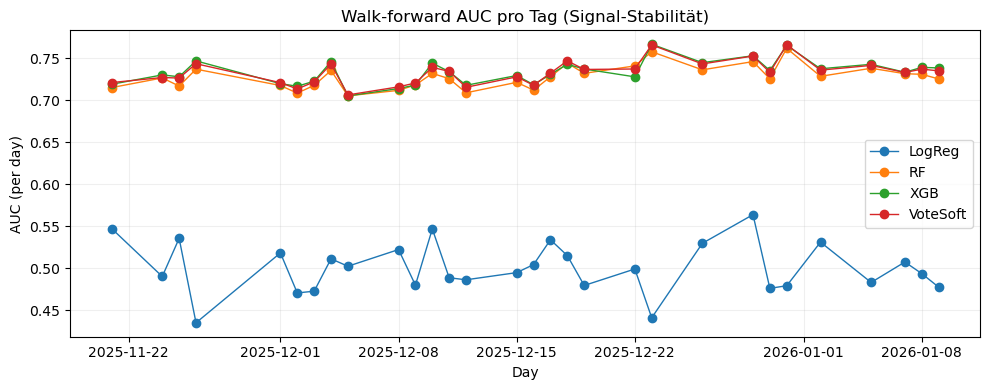

In [15]:
# Zelle 13: Bias/Variance-naher Plot: AUC-Verteilung über Tage (pro Modell)
plt.figure(figsize=(10, 4))
for m in final_scores["model"].unique():
    tmp = final_scores[final_scores["model"] == m].sort_values("day")
    plt.plot(tmp["day"], tmp["auc"], marker="o", linewidth=1, label=m)

plt.xlabel("Day")
plt.ylabel("AUC (per day)")
plt.title("Walk-forward AUC pro Tag (Signal-Stabilität)")
plt.grid(alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()


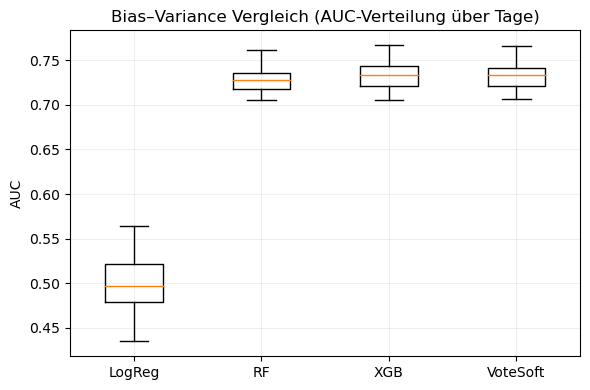

In [16]:
# Zelle 13b: Bias–Variance Summary – AUC-Verteilung pro Modell
plt.figure(figsize=(6, 4))

data = [
    final_scores[final_scores["model"] == m]["auc"].values
    for m in final_scores["model"].unique()
]

plt.boxplot(data, labels=final_scores["model"].unique(), showfliers=False)
plt.ylabel("AUC")
plt.title("Bias–Variance Vergleich (AUC-Verteilung über Tage)")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


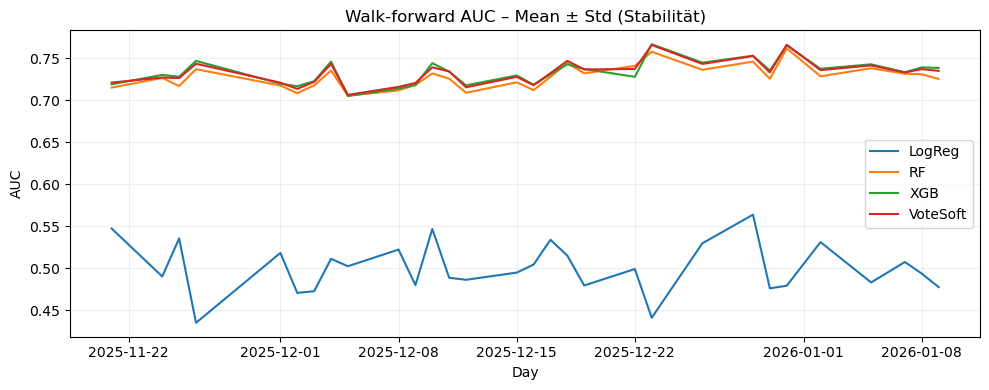

In [17]:
# Zelle 13c: Signal-Stabilität pro Modell (Mean ± Std über Tage)
plt.figure(figsize=(10, 4))

for m in final_scores["model"].unique():
    tmp = final_scores[final_scores["model"] == m].sort_values("day")
    mean_auc = tmp.groupby("day")["auc"].mean()
    std_auc = tmp.groupby("day")["auc"].std()

    plt.plot(mean_auc.index, mean_auc.values, label=m)
    plt.fill_between(
        mean_auc.index,
        mean_auc - std_auc,
        mean_auc + std_auc,
        alpha=0.2
    )

plt.xlabel("Day")
plt.ylabel("AUC")
plt.title("Walk-forward AUC – Mean ± Std (Stabilität)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


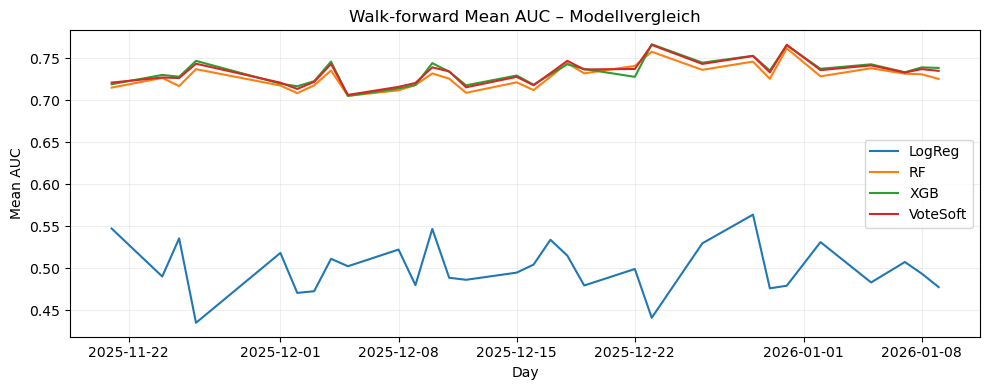

In [18]:
# Zelle 13d: Modellvergleich – Mean AUC (ohne Streuung)

plt.figure(figsize=(10, 4))

for m in final_scores["model"].unique():
    tmp = final_scores[final_scores["model"] == m]
    mean_auc = tmp.groupby("day")["auc"].mean()
    plt.plot(mean_auc.index, mean_auc.values, label=m)

plt.xlabel("Day")
plt.ylabel("Mean AUC")
plt.title("Walk-forward Mean AUC – Modellvergleich")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [19]:
# Zelle 14: Parameter-Sensitivität (Validation-Curve-ähnlich, manuell & time-safe)
# Wir variieren 1–2 zentrale Parameter und re-evaluieren walk-forward (kleines Grid)

rf_grid = {
    "clf__max_depth": [3, 5, None],
    "clf__min_samples_leaf": [5, 10, 20],
}

xgb_grid = {
    "clf__max_depth": [3, 4, 5],
    "clf__learning_rate": [0.03, 0.05, 0.1],
}

def eval_grid_for_model(model_name: str, param_grid: dict, k: int) -> pd.DataFrame:
    rows = []

    for params in ParameterGrid(param_grid):
        models[model_name].set_params(**params)

        mean_auc = walk_forward_score(
            k=k,
            model_name=model_name,
            day_stride=TUNING_DAY_STRIDE,
            verbose=False,
        )

        row = {
            "model": model_name,
            "k": k,
            "mean_auc": mean_auc,
            **params,
        }
        rows.append(row)

        print(
            model_name,
            params,
            "=> mean_auc:",
            round(mean_auc, 4),
        )

    return pd.DataFrame(rows).sort_values("mean_auc", ascending=False)


print("RF grid eval:")
rf_tuning = eval_grid_for_model("RF", rf_grid, k=best_k)

print("\nXGB grid eval:")
xgb_tuning = eval_grid_for_model("XGB", xgb_grid, k=best_k)

display(rf_tuning)
display(xgb_tuning)


RF grid eval:
RF {'clf__max_depth': 3, 'clf__min_samples_leaf': 5} => mean_auc: 0.721
RF {'clf__max_depth': 3, 'clf__min_samples_leaf': 10} => mean_auc: 0.721
RF {'clf__max_depth': 3, 'clf__min_samples_leaf': 20} => mean_auc: 0.7209
RF {'clf__max_depth': 5, 'clf__min_samples_leaf': 5} => mean_auc: 0.7335
RF {'clf__max_depth': 5, 'clf__min_samples_leaf': 10} => mean_auc: 0.7334
RF {'clf__max_depth': 5, 'clf__min_samples_leaf': 20} => mean_auc: 0.7333
RF {'clf__max_depth': None, 'clf__min_samples_leaf': 5} => mean_auc: 0.7173
RF {'clf__max_depth': None, 'clf__min_samples_leaf': 10} => mean_auc: 0.7234
RF {'clf__max_depth': None, 'clf__min_samples_leaf': 20} => mean_auc: 0.7284

XGB grid eval:
XGB {'clf__learning_rate': 0.03, 'clf__max_depth': 3} => mean_auc: 0.735
XGB {'clf__learning_rate': 0.03, 'clf__max_depth': 4} => mean_auc: 0.7325
XGB {'clf__learning_rate': 0.03, 'clf__max_depth': 5} => mean_auc: 0.7301
XGB {'clf__learning_rate': 0.05, 'clf__max_depth': 3} => mean_auc: 0.732
XGB {'

,model,k,mean_auc,clf__max_depth,clf__min_samples_leaf
3,RF,5,0.733498,5.0,5
4,RF,5,0.733358,5.0,10
5,RF,5,0.733298,5.0,20
8,RF,5,0.728387,NaN,20
7,RF,5,0.723441,NaN,10
0,RF,5,0.721021,3.0,5
1,RF,5,0.720993,3.0,10
2,RF,5,0.720934,3.0,20
6,RF,5,0.717325,NaN,5


,model,k,mean_auc,clf__learning_rate,clf__max_depth
0,XGB,5,0.734973,0.03,3
1,XGB,5,0.732488,0.03,4
3,XGB,5,0.732043,0.05,3
2,XGB,5,0.730091,0.03,5
4,XGB,5,0.729498,0.05,4
6,XGB,5,0.725609,0.10,3
5,XGB,5,0.725487,0.05,5
7,XGB,5,0.720843,0.10,4
8,XGB,5,0.717011,0.10,5


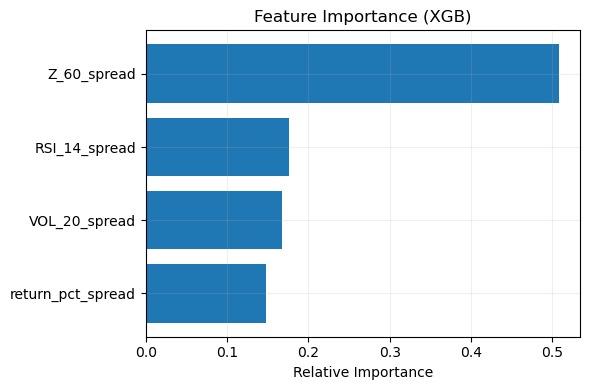

In [20]:
# %%
# Zelle 16c: Feature Importance (XGB)

xgb_clf = models["XGB"].named_steps["clf"]

feature_names = [
    f"RSI_{RSI_W}_spread",
    f"Z_{Z_W}_spread",
    f"VOL_{VOL_W}_spread",
    "return_pct_spread",
]

imp_df = pd.DataFrame({
    "feature": feature_names,
    "importance": xgb_clf.feature_importances_,
}).sort_values("importance", ascending=True)

plt.figure(figsize=(6, 4))
plt.barh(imp_df["feature"], imp_df["importance"])
plt.xlabel("Relative Importance")
plt.title("Feature Importance (XGB)")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


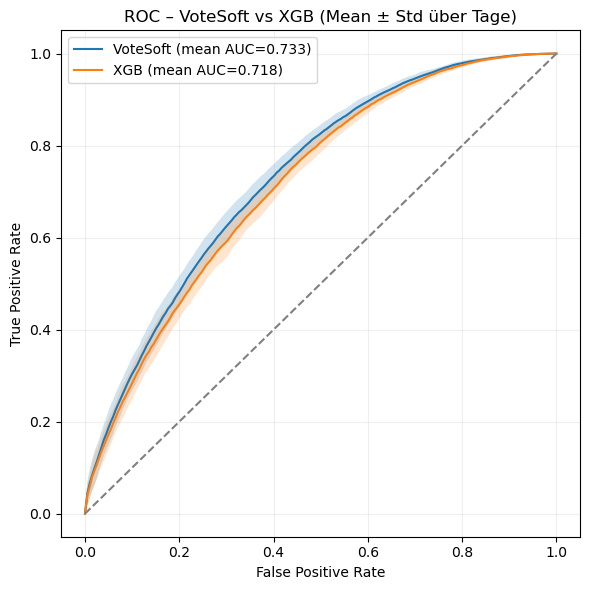

In [21]:
# %%
# Zelle 16d: ROC (Mean ± Std) – Vergleich VoteSoft vs XGB

from sklearn.metrics import roc_curve

def roc_mean_std_band(model_name: str, k: int):
    fpr_grid = np.linspace(0.0, 1.0, 200)
    tprs = []
    aucs = []

    model = models[model_name]

    for day in test_days:
        idx_day = all_days.get_loc(day)
        train_days = all_days[idx_day - LOOKBACK_TRAIN_DAYS : idx_day]

        lp_train = _slice_by_days(log_prices, train_days)
        lp_test = _slice_by_days(log_prices, pd.Index([day]))

        _, top_pairs_df = get_pairs_for_test_day(day, all_days, log_prices)
        if top_pairs_df.empty:
            continue

        pairs = list(
            top_pairs_df[["symbol1", "symbol2"]]
            .itertuples(index=False, name=None)
        )

        panel_train = features.build_feature_panel(lp_train, pairs, RSI_W, Z_W, VOL_W)
        panel_test = features.build_feature_panel(lp_test, pairs, RSI_W, Z_W, VOL_W)

        X_train, y_train, _ = build_Xy_from_feature_panel(panel_train, k=k)
        X_test, y_test, _ = build_Xy_from_feature_panel(panel_test, k=k)

        if len(y_test) < 50:
            continue

        model.fit(X_train, y_train)
        proba = model.predict_proba(X_test)[:, 1]

        fpr, tpr, _ = roc_curve(y_test, proba)
        tpr_interp = np.interp(fpr_grid, fpr, tpr)
        tpr_interp[0] = 0.0

        tprs.append(tpr_interp)
        aucs.append(roc_auc_score(y_test, proba))

    tprs = np.array(tprs)
    mean_tpr = tprs.mean(axis=0)
    std_tpr = tprs.std(axis=0)
    mean_auc = float(np.mean(aucs)) if aucs else np.nan

    return fpr_grid, mean_tpr, std_tpr, mean_auc


fpr_v, mean_v, std_v, auc_v = roc_mean_std_band("VoteSoft", k=best_k)
fpr_x, mean_x, std_x, auc_x = roc_mean_std_band("XGB", k=best_k)

plt.figure(figsize=(6, 6))

plt.plot(fpr_v, mean_v, label=f"VoteSoft (mean AUC={auc_v:.3f})")
plt.fill_between(fpr_v, mean_v - std_v, mean_v + std_v, alpha=0.20)

plt.plot(fpr_x, mean_x, label=f"XGB (mean AUC={auc_x:.3f})")
plt.fill_between(fpr_x, mean_x - std_x, mean_x + std_x, alpha=0.20)

plt.plot([0, 1], [0, 1], linestyle="--", color="grey")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC – VoteSoft vs XGB (Mean ± Std über Tage)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


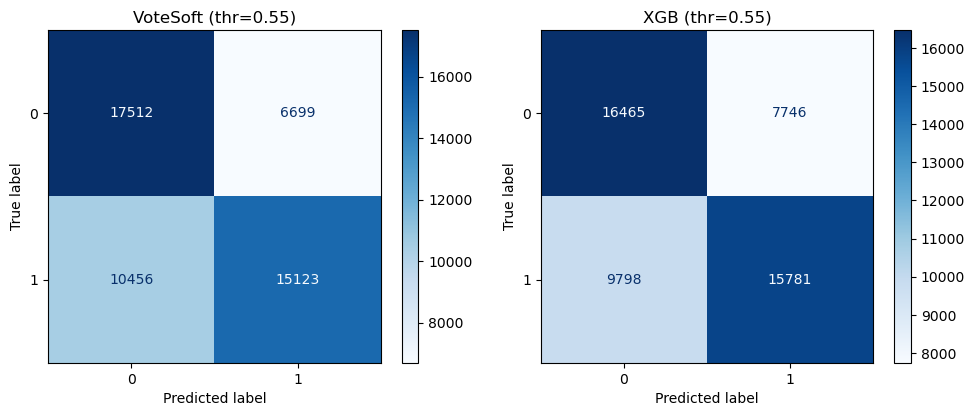

In [22]:
# %%
# Zelle 16e: Confusion Matrix – Vergleich VoteSoft vs XGB (gleicher Threshold)

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def confusion_for_model(model_name: str, k: int, threshold: float):
    y_true_all = []
    y_pred_all = []

    model = models[model_name]

    for day in test_days:
        idx_day = all_days.get_loc(day)
        train_days = all_days[idx_day - LOOKBACK_TRAIN_DAYS : idx_day]

        lp_train = _slice_by_days(log_prices, train_days)
        lp_test = _slice_by_days(log_prices, pd.Index([day]))

        _, top_pairs_df = get_pairs_for_test_day(day, all_days, log_prices)
        if top_pairs_df.empty:
            continue

        pairs = list(
            top_pairs_df[["symbol1", "symbol2"]]
            .itertuples(index=False, name=None)
        )

        panel_train = features.build_feature_panel(lp_train, pairs, RSI_W, Z_W, VOL_W)
        panel_test = features.build_feature_panel(lp_test, pairs, RSI_W, Z_W, VOL_W)

        X_train, y_train, _ = build_Xy_from_feature_panel(panel_train, k=k)
        X_test, y_test, _ = build_Xy_from_feature_panel(panel_test, k=k)

        if len(y_test) < 50:
            continue

        model.fit(X_train, y_train)
        proba = model.predict_proba(X_test)[:, 1]

        y_true_all.extend(y_test.values)
        y_pred_all.extend((proba > threshold).astype(int))

    cm = confusion_matrix(y_true_all, y_pred_all)
    return cm


threshold = 0.55
cm_vote = confusion_for_model("VoteSoft", k=best_k, threshold=threshold)
cm_xgb = confusion_for_model("XGB", k=best_k, threshold=threshold)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
disp1 = ConfusionMatrixDisplay(cm_vote)
disp1.plot(cmap="Blues", values_format="d", ax=plt.gca())
plt.title(f"VoteSoft (thr={threshold})")

plt.subplot(1, 2, 2)
disp2 = ConfusionMatrixDisplay(cm_xgb)
disp2.plot(cmap="Blues", values_format="d", ax=plt.gca())
plt.title(f"XGB (thr={threshold})")

plt.tight_layout()
plt.show()


In [23]:
# %%
# Zelle 17: Trading-Inspektion – Daily PnL (Sanity-Check, kein Backtest)

MODEL_FOR_TRADING = "XGB"
THRESHOLD = 0.55
TCOST_BP = 4        # round-trip, beide Legs inkludiert
ROLL_W = 10         # Rolling Window (Handelstage)

trade_df = walk_forward_collect_trading_artifacts(
    model_name=MODEL_FOR_TRADING,
    k=best_k,
)

trades = trade_df.copy()

# Trading-Regel
trades["enter"] = trades["proba"] > THRESHOLD
trades["direction"] = np.where(trades["z"] > 0, -1, 1)

trades["gross_pnl"] = trades["direction"] * trades["spread_ret_k"]
trades["cost"] = TCOST_BP / 1e4
trades["net_pnl"] = np.where(
    trades["enter"],
    trades["gross_pnl"] - trades["cost"],
    0.0,
)

daily = (
    trades.groupby("day")
    .agg(
        pnl=("net_pnl", "sum"),
        n_trades=("enter", "sum"),
        hit_rate=("gross_pnl", lambda x: (x > 0).mean()),
    )
    .reset_index()
)

daily["equity"] = daily["pnl"].cumsum()
daily["drawdown"] = daily["equity"] - daily["equity"].cummax()

daily["roll_mu"] = daily["pnl"].rolling(ROLL_W, min_periods=5).mean()
daily["roll_sd"] = daily["pnl"].rolling(ROLL_W, min_periods=5).std()

display(daily.head())


,day,pnl,n_trades,hit_rate,equity,drawdown,roll_mu,roll_sd
0,2025-11-21 00:00:00+00:00,-34.743649,801,0.450765,-34.743649,0.000000,NaN,NaN
1,2025-11-24 00:00:00+00:00,-47.566871,800,0.430581,-82.310520,-47.566871,NaN,NaN
2,2025-11-25 00:00:00+00:00,-35.668537,802,0.451376,-117.979057,-83.235408,NaN,NaN
3,2025-11-26 00:00:00+00:00,-91.520462,734,0.445872,-209.499519,-174.755870,NaN,NaN
4,2025-12-01 00:00:00+00:00,-62.253278,771,0.436697,-271.752797,-237.009148,-54.350559,23.577118


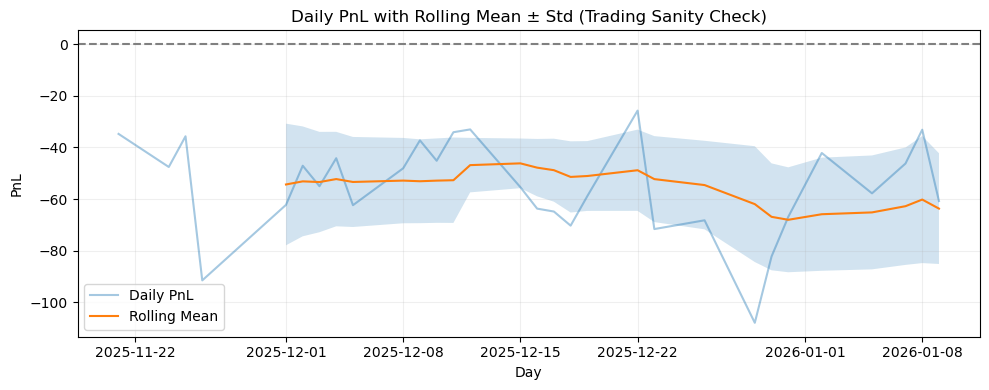

In [24]:
# %%
# Zelle 17b: Daily PnL – Rolling Mean ± Std

plt.figure(figsize=(10, 4))

plt.plot(daily["day"], daily["pnl"], alpha=0.4, label="Daily PnL")
plt.plot(daily["day"], daily["roll_mu"], label="Rolling Mean")

plt.fill_between(
    daily["day"],
    daily["roll_mu"] - daily["roll_sd"],
    daily["roll_mu"] + daily["roll_sd"],
    alpha=0.2,
)

plt.axhline(0, color="grey", linestyle="--")
plt.xlabel("Day")
plt.ylabel("PnL")
plt.title("Daily PnL with Rolling Mean ± Std (Trading Sanity Check)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


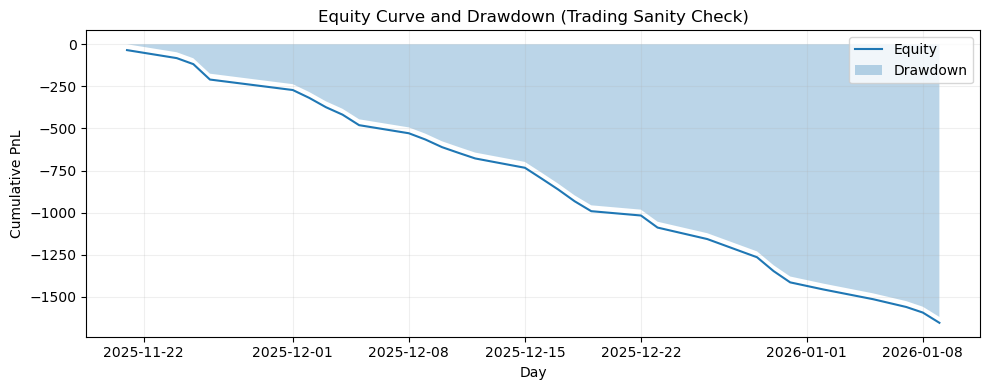

In [25]:
# %%
# Zelle 17c: Equity Curve & Drawdown

plt.figure(figsize=(10, 4))

plt.plot(daily["day"], daily["equity"], label="Equity")
plt.fill_between(
    daily["day"],
    daily["drawdown"],
    0,
    alpha=0.3,
    label="Drawdown",
)

plt.xlabel("Day")
plt.ylabel("Cumulative PnL")
plt.title("Equity Curve and Drawdown (Trading Sanity Check)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


---

<div style="display: flex; justify-content: space-between; margin-top: 30px;">
  <a href="04_Explorative_Datenanalyse.ipynb">
    <button style="background-color:#007acc;color:white;border:none;padding:8px 12px;border-radius:6px;cursor:pointer;">
      Zurück
    </button>
  </a>
  <a href="06_.ipynb">
    <button style="background-color:#007acc;color:white;border:none;padding:8px 12px;border-radius:6px;cursor:pointer;">
      Weiter
    </button>
  </a>
</div>
